#### Imports and configurations

In [48]:
"""
Day 1 - API Data Analysis Using Python Structures
Squad Python Specialization - Data Science, AI & Analytics
"""
import json
from pathlib import Path
OUTPUT_DIR = Path("output")

import matplotlib.pyplot as plt
import pandas as pd
import requests

API_URL = "https://jsonplaceholder.typicode.com/users"


#### Retrieving customer data

In [49]:
def get_customers(url: str = API_URL) -> list[dict]:
    """Fetch the customer list. Report failures clearly instead of crashing."""
    try:
        response = requests.get(url, timeout = 10)
        response.raise_for_status()

        customers = response.json()

        if not isinstance(customers, list):
            raise ValueError("Expected a list of customers.")

        return customers
    
    except (requests.RequestException, ValueError) as error:
        print(f"Failed to retrieve customers: {error}")
        return []

    


In [50]:
customers = get_customers()
print(f"Total customers: {len(customers)}")
display(customers[0])

Total customers: 10


{'id': 1,
 'name': 'Leanne Graham',
 'username': 'Bret',
 'email': 'Sincere@april.biz',
 'address': {'street': 'Kulas Light',
  'suite': 'Apt. 556',
  'city': 'Gwenborough',
  'zipcode': '92998-3874',
  'geo': {'lat': '-37.3159', 'lng': '81.1496'}},
 'phone': '1-770-736-8031 x56442',
 'website': 'hildegard.org',
 'company': {'name': 'Romaguera-Crona',
  'catchPhrase': 'Multi-layered client-server neural-net',
  'bs': 'harness real-time e-markets'}}

#### Exploring nested dictionaries and lists

In [51]:
def explore(record: dict, indent: int = 0) -> None:
    """Print every key in a (possibly nested) record with its type, indented by depth."""

    prefix = " "* indent

    if isinstance(record, dict):
        for key, value in record.items():
            print(f"{prefix}{key}: {type(value).__name__}")
            explore(value, indent + 2)

    elif isinstance(record, list):
        for index, value in enumerate(record):
            print(f"{prefix}[{index}]: {type(value).__name__}")
            explore(value, indent + 2)
    

In [52]:
explore(customers[9])

id: int
name: str
username: str
email: str
address: dict
  street: str
  suite: str
  city: str
  zipcode: str
  geo: dict
    lat: str
    lng: str
phone: str
website: str
company: dict
  name: str
  catchPhrase: str
  bs: str


#### Extracting and flattening customer attributes

In [53]:
def extract_attributes(customers: list[dict]) -> list[dict]:
    """Return one flat dict per customer with the attributes listed in the task."""
    rows = []

    for customer in customers:
        # Extract internal dictionaries safely
        address = customer.get("address") or {}
        geo = address.get("geo") or {}
        company = customer.get("company") or {}

        # Isolate the clean email and extract the Top-Level Domain (TLD)
        email = customer.get("email") or ""
        email_domain = (
            email.split(".")[-1].lower()
            if "." in email
            else None
        )

        rows.append({
            "id": customer.get("id"),
            "name": customer.get("name"),
            "username": customer.get("username"),
            "email": email,
            "email_domain": email_domain,
            "phone": customer.get("phone"),
            "city": address.get("city"),       # Fixed: Pulled from address dict
            "zipcode": address.get("zipcode"), # Fixed: Pulled from address dict
            "latitude": (
                float(geo["lat"]) if geo.get("lat") is not None else None
            ),
            "longitude": (
                float(geo["lng"]) if geo.get("lng") is not None else None
            ),
            "company": company.get("name"),
            "website": customer.get("website"), # Fixed: website is top-level in this API
        })

    return rows


In [54]:
rows = extract_attributes(customers)
print(json.dumps(rows[0], indent=4))

{
    "id": 1,
    "name": "Leanne Graham",
    "username": "Bret",
    "email": "Sincere@april.biz",
    "email_domain": "biz",
    "phone": "1-770-736-8031 x56442",
    "city": "Gwenborough",
    "zipcode": "92998-3874",
    "latitude": -37.3159,
    "longitude": 81.1496,
    "company": "Romaguera-Crona",
    "website": "hildegard.org"
}


#### Finding unique cities using a set

In [55]:

def unique_cities(customers: list[dict]) -> set[str]:
    """Return the set of distinct cities."""
    return{
        customer["address"]["city"]
        for customer in customers
        if customer.get("address") and customer["address"].get("city")
    }

In [56]:
cities = unique_cities(customers)
print(f"Total customers: {len(customers)}")
print(f"Unique cities: {len(cities)}")
print(f"Cities: {sorted(cities)}")

Total customers: 10
Unique cities: 10
Cities: ['Aliyaview', 'Bartholomebury', 'Gwenborough', 'Howemouth', 'Lebsackbury', 'McKenziehaven', 'Roscoeview', 'South Christy', 'South Elvis', 'Wisokyburgh']


#### Counting customers by city

In [57]:
def city_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per city using a loop and/or a dict comprehension (no Counter, no pandas)."""
    counts = {}

    for customer in customers:
        address = customer.get("address") or {}
        city = address.get("city")

        if city:
            counts[city] = counts.get(city, 0)+ 1

    return counts

In [58]:
cities_count = city_counts(customers)
for city, count in sorted(
    cities_count.items(),
    key=lambda item: (-item[1], item[0])
):
   print(f"{city}: {count}")

Aliyaview: 1
Bartholomebury: 1
Gwenborough: 1
Howemouth: 1
Lebsackbury: 1
McKenziehaven: 1
Roscoeview: 1
South Christy: 1
South Elvis: 1
Wisokyburgh: 1


#### Counting customers by email

In [59]:
def email_domain_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per email top-level domain (e.g. 'biz', 'tv')."""
    domain_counts = {}
    
    for customer in customers:
        email = customer.get("email", "")
        
        # Split by the dot to isolate the very last segment (the top-level domain)
        if "." in email:
            tld = email.split(".")[-1]
            
            # Increment the count in our dictionary
            domain_counts[tld] = domain_counts.get(tld, 0) + 1
            
    return domain_counts


In [60]:
customers = get_customers()
counts = email_domain_counts(customers)
print(counts)


{'biz': 3, 'tv': 1, 'net': 1, 'org': 1, 'ca': 1, 'info': 1, 'me': 1, 'io': 1}


In [61]:
def to_dataframe(rows: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(rows)


In [62]:
df = to_dataframe(rows)
print("DataFrame shape:", df.shape)
display(df)
print("\n Column datatypes:")
print(df.dtypes)

DataFrame shape: (10, 12)


,id,name,username,email,email_domain,phone,city,zipcode,latitude,longitude,company,website
0,1,Leanne Graham,Bret,Sincere@april.biz,biz,1-770-736-8031 x56442,Gwenborough,92998-3874,-37.3159,81.1496,Romaguera-Crona,hildegard.org
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,tv,010-692-6593 x09125,Wisokyburgh,90566-7771,-43.9509,-34.4618,Deckow-Crist,anastasia.net
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,net,1-463-123-4447,McKenziehaven,59590-4157,-68.6102,-47.0653,Romaguera-Jacobson,ramiro.info
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,org,493-170-9623 x156,South Elvis,53919-4257,29.4572,-164.2990,Robel-Corkery,kale.biz
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,ca,(254)954-1289,Roscoeview,33263,-31.8129,62.5342,Keebler LLC,demarco.info
5,6,Mrs. Dennis Schulist,Leopoldo_Corkery,Karley_Dach@jasper.info,info,1-477-935-8478 x6430,South Christy,23505-1337,-71.4197,71.7478,Considine-Lockman,ola.org
6,7,Kurtis Weissnat,Elwyn.Skiles,Telly.Hoeger@billy.biz,biz,210.067.6132,Howemouth,58804-1099,24.8918,21.8984,Johns Group,elvis.io
7,8,Nicholas Runolfsdottir V,Maxime_Nienow,Sherwood@rosamond.me,me,586.493.6943 x140,Aliyaview,45169,-14.3990,-120.7677,Abernathy Group,jacynthe.com
8,9,Glenna Reichert,Delphine,Chaim_McDermott@dana.io,io,(775)976-6794 x41206,Bartholomebury,76495-3109,24.6463,-168.8889,Yost and Sons,conrad.com
9,10,Clementina DuBuque,Moriah.Stanton,Rey.Padberg@karina.biz,biz,024-648-3804,Lebsackbury,31428-2261,-38.2386,57.2232,Hoeger LLC,ambrose.net



 Column datatypes:
id                int64
name                str
username            str
email               str
email_domain        str
phone               str
city                str
zipcode             str
latitude        float64
longitude       float64
company             str
website             str
dtype: object


In [63]:
df["city"].value_counts() 

city
Gwenborough       1
Wisokyburgh       1
McKenziehaven     1
South Elvis       1
Roscoeview        1
South Christy     1
Howemouth         1
Aliyaview         1
Bartholomebury    1
Lebsackbury       1
Name: count, dtype: int64

#### Export to csv file

In [64]:
df.to_csv(OUTPUT_DIR / "customers.csv", index=False)

city_summary = pd.DataFrame(
    sorted(
        cities_count.items(),
        key=lambda item: (-item[1], item[0])
    ),
    columns=["city", "customer_count"]
) 

city_summary.to_csv(
    OUTPUT_DIR / "city_counts.csv",
    index=False
)

print("CSV files saved:")
print(OUTPUT_DIR / "customers.csv")
print(OUTPUT_DIR / "city_counts.csv")

CSV files saved:
output\customers.csv
output\city_counts.csv


#### Plotting the customer distribution by city

In [65]:
def plot_distribution(counts: dict[str, int], path: Path) -> None:
    """Save a labelled bar chart of customer counts."""
    sorted_counts = dict(
        sorted(counts.items(), key=lambda item: (-item[1], item[0]))
    )

    plt.figure(figsize=(10, 6))
    plt.bar(sorted_counts.keys(), sorted_counts.values())

    plt.title("Pesa Pulse: Customer Distribution by City")
    plt.xlabel("City")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

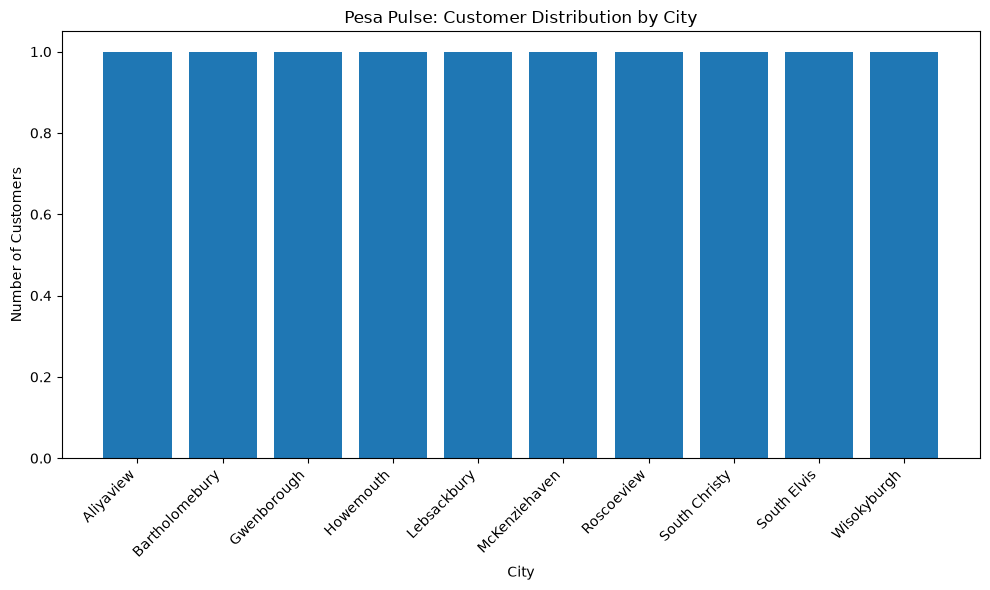

In [66]:
plot_distribution(
    cities_count,
    OUTPUT_DIR / "customer_distribution.png"
)

#### Plotting the customer distribution by email(TLD)

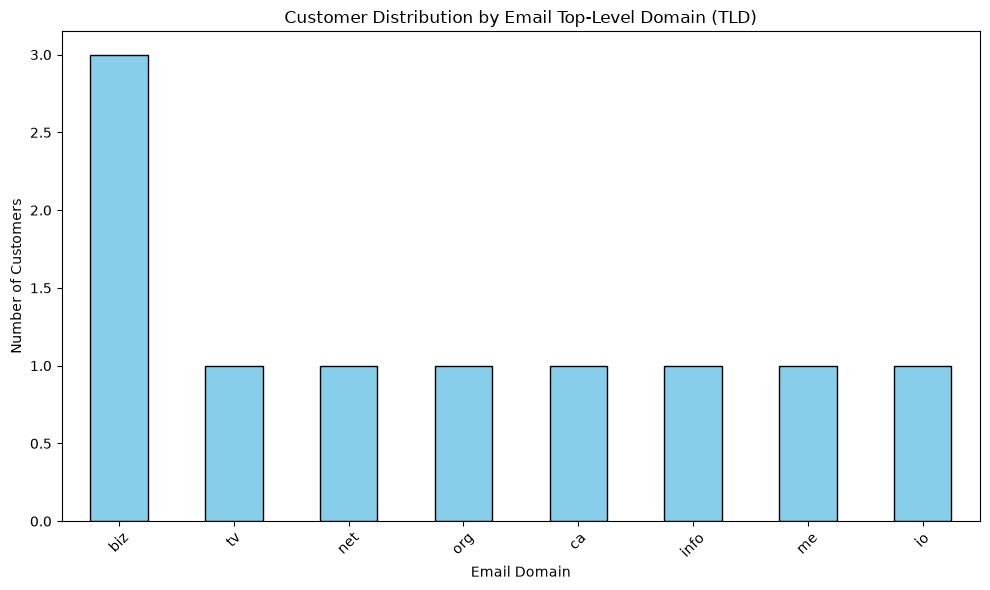

Chart successfully saved to: output\email_domain_distribution.png


In [67]:


# Defining my output directory path
OUTPUT_DIR = Path("output")

# domain counts data
counts_dict = email_domain_counts(customers)
domain_series = pd.Series(counts_dict).sort_values(ascending=False)

#  Build the chart layout
plt.figure(figsize=(10, 6))

domain_series.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Customer Distribution by Email Top-Level Domain (TLD)")
plt.xlabel("Email Domain")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()  # Prevents text labels from getting cut off

# Saving the figure to my output folder
plt.savefig(OUTPUT_DIR / "email_domain_distribution.png", dpi=300)

# Displaying the plot
plt.show()
print(f"Chart successfully saved to: {OUTPUT_DIR / 'email_domain_distribution.png'}")
